# Forward models for the Montreal River Monocline manuscript figures

### Import Python packages

In [1]:
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
import matplotlib.pyplot as plt
import pythermo as pyt

%matplotlib inline
%config InlineBackend.figure_format='retina'

### Load data from csv files

In [2]:
zircon_data = pd.read_csv("data/UTh_He_zircon_data.csv")
apatite_data = pd.read_csv("data/UTh_He_apatite_data.csv")

### High grade to data sets for forward model comparison

Get the zircon data first

In [3]:
#filter out spurious grains
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MRM20_z3']
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MRM34_z2']
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MA5_z1']
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MA5_z2']

# Split the 'Unnamed: 0' column which has the analysis name into three parts
splits_z = zircon_data['Unnamed: 0'].str.split('_', expand=True)
splits_a = apatite_data['Unnamed: 0'].str.split('_', expand=True)


# Assign the second part (index 1) to the new 'sample' column
zircon_data['sample'] = splits_z[1]
apatite_data['sample'] = splits_a[1]

# Assign the third part (index 2) to the new 'grain' column
zircon_data['grain'] = splits_z[2]
apatite_data['grain'] = splits_a[2]

MRM_Archean_samples = ['MRM1','MRM2','MRM4','MRM5','MRM6','MRM35','MRM20',
                       'MRM8','MRM17','MRM16','MRM7','MRM21', 'MRM36']

Other_Archean_samples = ['MRM24']
 
MRM_rift_samples = ['MRM9', 'MRM34', 'MC4']

MRM_Freda_samples = ['LRA','BRB']

MRM_Archean_data = zircon_data[zircon_data['sample'].isin(MRM_Archean_samples)]
Other_Archean_data = zircon_data[zircon_data['sample'].isin(Other_Archean_samples)]
MRM_rift_data = zircon_data[zircon_data['sample'].isin(MRM_rift_samples)]
MRM_Freda_data = zircon_data[zircon_data['sample'].isin(MRM_Freda_samples)]

Now get the apatite data

In [4]:
apatite_data['sample'] = apatite_data['sample'].replace('397', 'MC4')

MRM_apatite_samples = ['MRM35', 'MRM36', 'MC4', 'MRM16', 'MRM8', 'MRM6', 'MRM20', 'MRM21', 'MRM24']
MRM_apatite_samples_selected = ['MRM35', 'MRM36', 'MC4', 'MRM8', 'MRM6', 'MRM21', 'MRM24']

MRM_apatite_data = apatite_data[apatite_data['sample'].isin(MRM_apatite_samples_selected)]

Load the data into arrays formatted for input into PyThermo

In [5]:
ap_obs_data = np.zeros((13,4))

ap_obs_data[:,0] = MRM_apatite_data['corrected_date']
ap_obs_data[:,1] = MRM_apatite_data['corrected_1s']
ap_obs_data[:,2] = MRM_apatite_data['eU']
ap_obs_data[:,3] = MRM_apatite_data['radius']

zirc_obs_data = np.zeros((54,4))

zirc_obs_data[:,0] = MRM_Archean_data['corrected_date']
zirc_obs_data[:,1] = MRM_Archean_data['corrected_1s']
zirc_obs_data[:,2] = MRM_Archean_data['eU']
zirc_obs_data[:,3] = MRM_Archean_data['radius']

### Create input model data frame and tT arrays

Model data frame first

In [6]:
ap_dict = {'mineral type':['apatite', 'apatite', 'apatite','apatite','apatite','apatite','apatite'], 'age':[60,80,90,0,0,0,0],'error':[2,2,2,0,0,0,0],'size':[60,60,60,60,60,60,60],'U ppm':[10,20,40,60,80,100,125],'Th ppm':[0,0,0,0,0,0,0],'Sm ppm':[0,0,0,0,0,0,0],'diffusion model':['flowers','flowers','flowers','flowers','flowers','flowers','flowers'],'annealing model':['ketcham','ketcham','ketcham','ketcham','ketcham','ketcham','ketcham']}

ap_grain_in = pd.DataFrame(data=ap_dict,
                        columns = ['mineral type', 'age', 'error','size','U ppm', 'Th ppm', 'Sm ppm', 'diffusion model', 'annealing model'],
                        index = ['ap 1', 'ap 2', 'ap 3','ap 4','ap 5','ap 6', 'ap 7'])

zirc_dict = {'mineral type':['zircon', 'zircon', 'zircon','zircon','zircon','zircon','zircon','zircon','zircon','zircon','zircon'], 'age':[60,80,90,0,0,0,0,0,0,0,0],'error':[2,2,2,0,0,0,0,0,0,0,0],'size':[60,60,60,60,60,60,60,60,60,60,60],'U ppm':[50,100,250,500,750,1000,1250,1500,2000,3000,4500],'Th ppm':[0,0,0,0,0,0,0,0,0,0,0],'Sm ppm':[0,0,0,0,0,0,0,0,0,0,0],'diffusion model':['guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner'],'annealing model':['guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner']}

zirc_grain_in = pd.DataFrame(data=zirc_dict,
                        columns = ['mineral type', 'age', 'error','size','U ppm', 'Th ppm', 'Sm ppm', 'diffusion model', 'annealing model'],
                        index = ['zirc 1', 'zirc 2', 'zirc 3','zirc 4','zirc 5','zirc 6', 'zirc 7', 'zirc 8', 'zirc 9','zirc 10','zirc 11'])

Select Neoproterozoic time-temperature path arrays for the Neoproterozoic forward figure.

In [7]:
#apatite tT paths

tT_ap_neo_heat = np.array([[0,10,0,10,0,10],[250,80,250,80,250,80],[505,10,505,10,505,10],[990,65,990,75,990,85],[1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160],])

tT_ap_neo_cool = np.array([[0,10,0,10,0,10,0,10],[250,80,250,80,250,80,250,80],[505,10,505,10,505,10,505,10],[550,75,650,75,750,75,850,75],[990,75,990,75,990,75,990,75],[1040,10,1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160,1050,160],])

#zircon tT paths

tT_zirc_neo_heat = np.array([[0,10,0,10,0,10],[250,80,250,80,250,80],[505,10,505,10,505,10],[990,65,990,75,990,85],[1040,10,1040,10,1040,10],[1050,200,1050,200,1050,200],[1100,10,1100,10,1100,10],[1840,100,1840,100,1840,100]])

tT_zirc_neo_cool = np.array([[0,10,0,10,0,10,0,10],[250,80,250,80,250,80,250,80],[505,10,505,10,505,10,505,10],[550,75,650,75,750,75,850,75],[990,75,990,75,990,75,990,75],[1040,10,1040,10,1040,10,1040,10],[1050,200,1050,200,1050,200,1050,200],[1100,10,1100,10,1100,10,1100,10],[1840,100,1840,100,1840,100,1840,100]])

### Run the models

The next four cells run the Neoproterozoic models and save them as separate files.

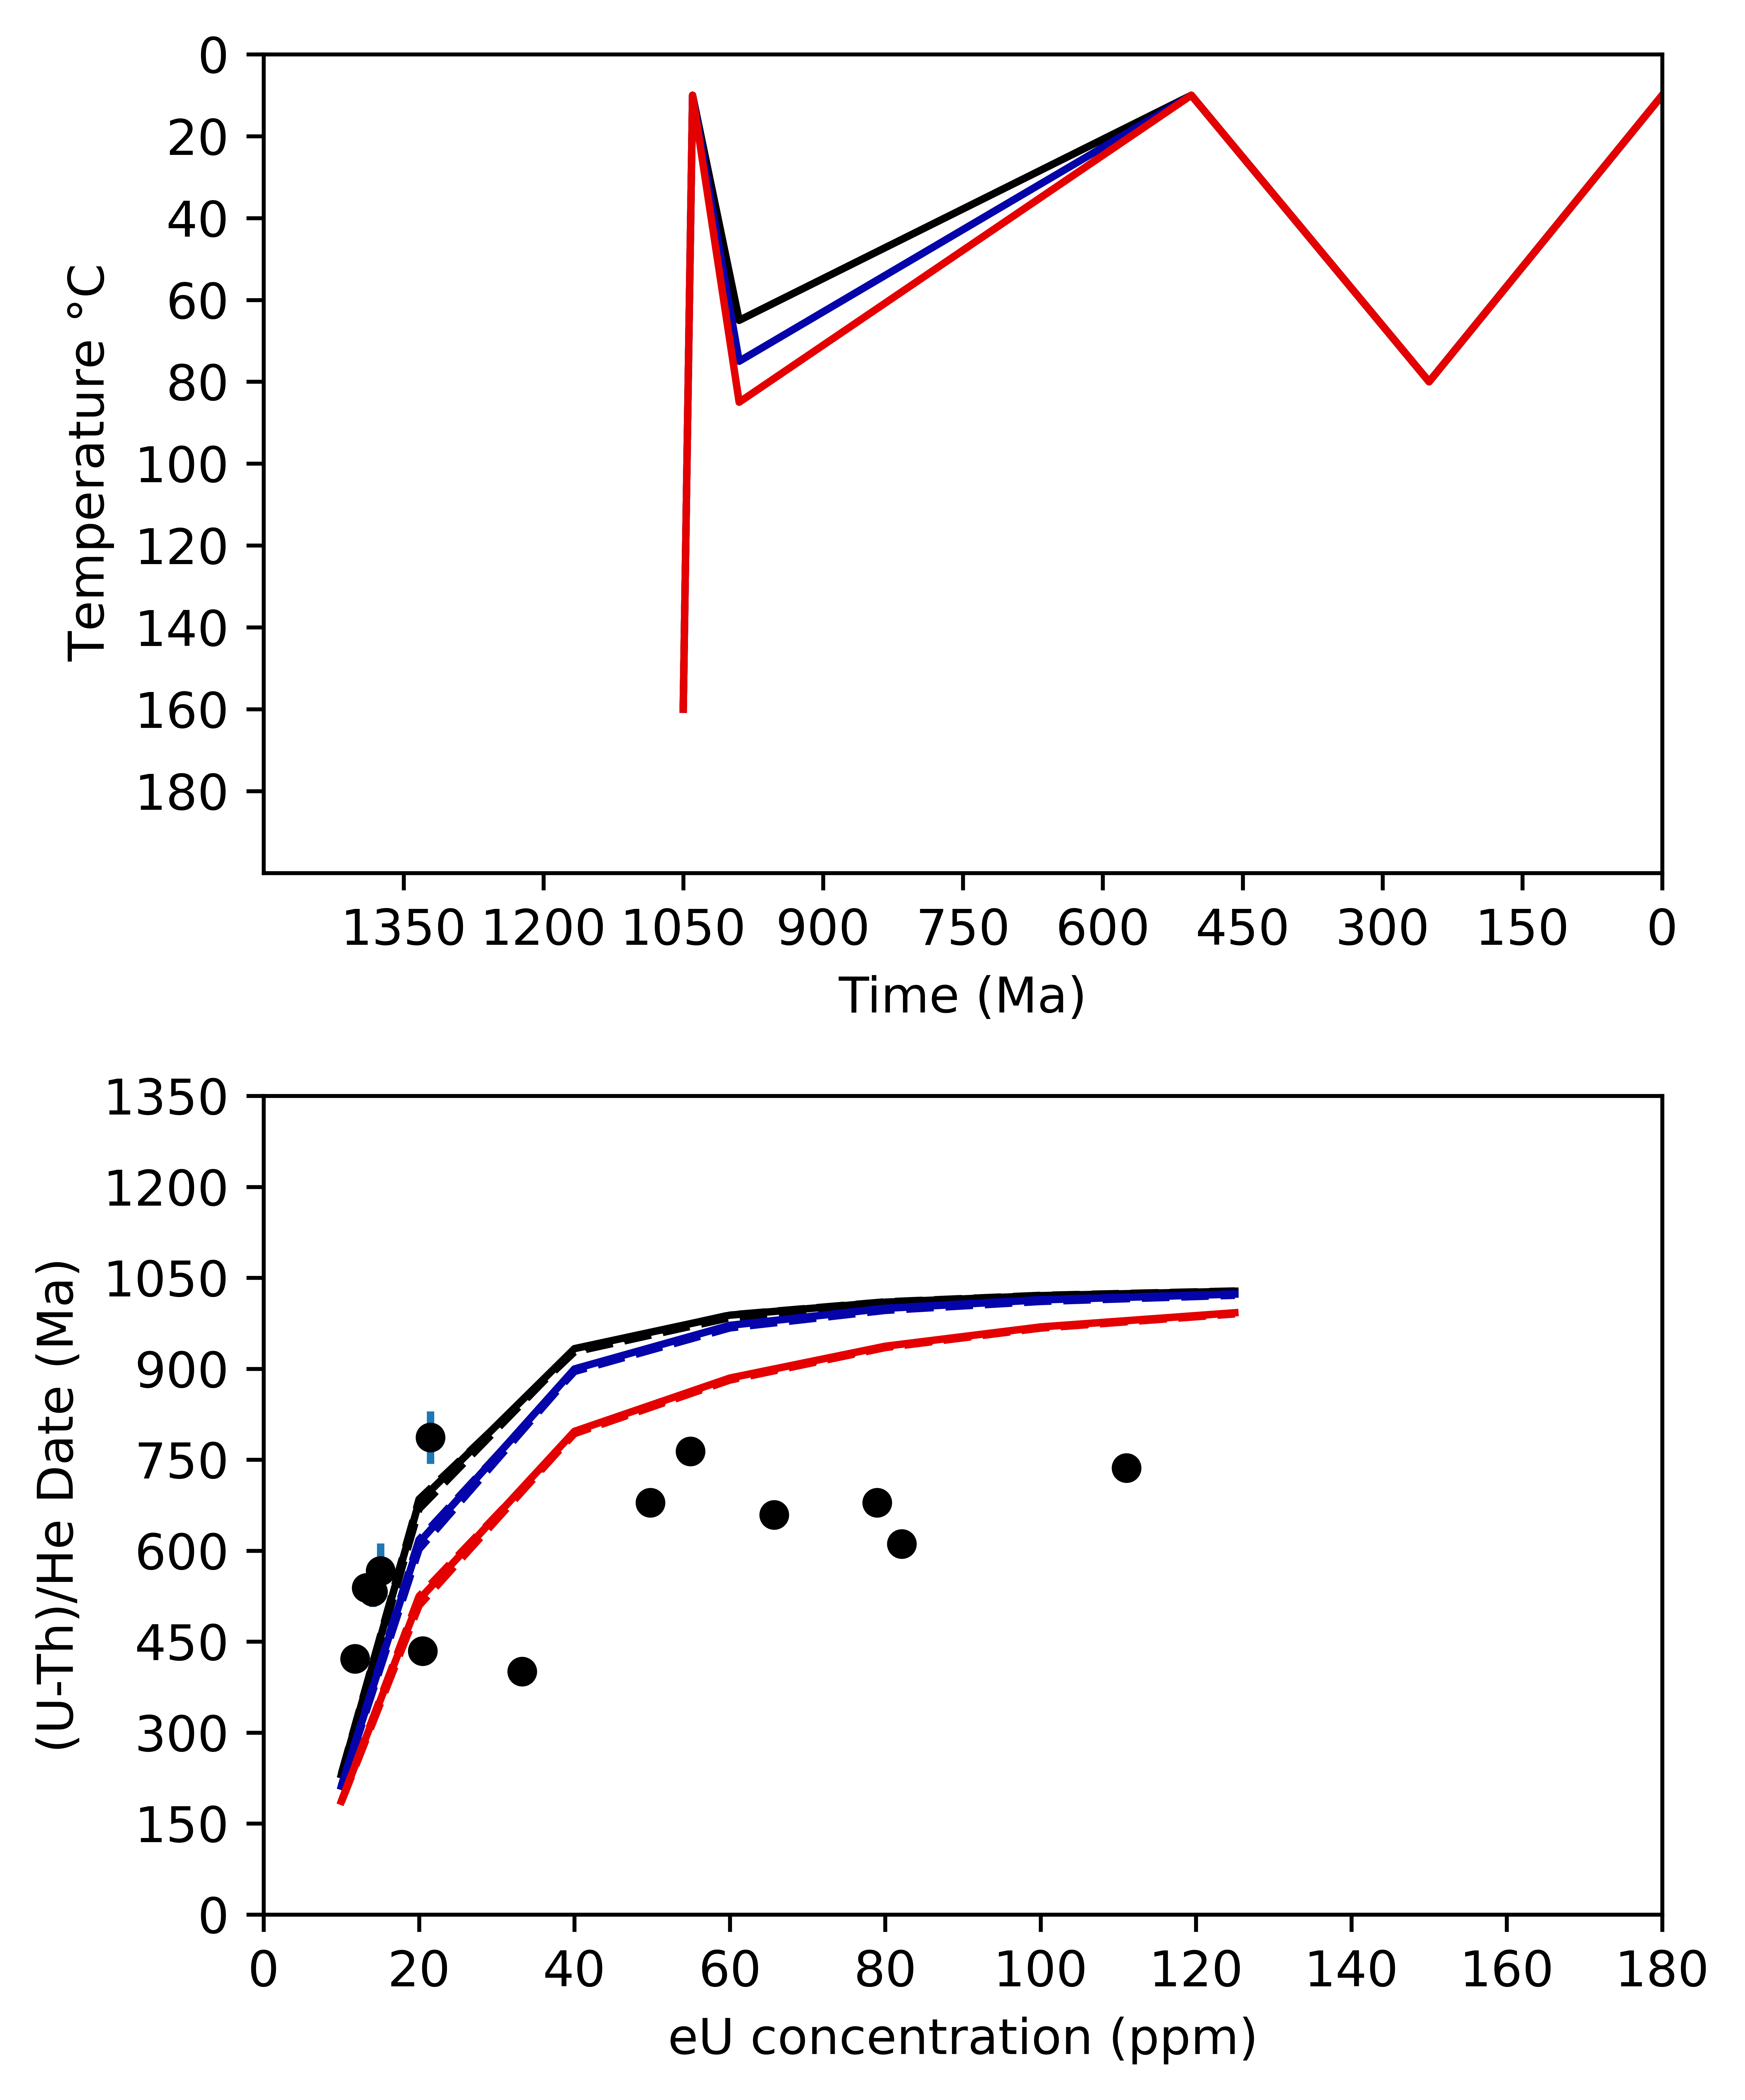

In [8]:
ap_neo_heat_path = pyt.tT_model(ap_grain_in,tT_ap_neo_heat,ap_obs_data)
ap_neo_heat_fig = ap_neo_heat_path.forward(log2_nodes=7)

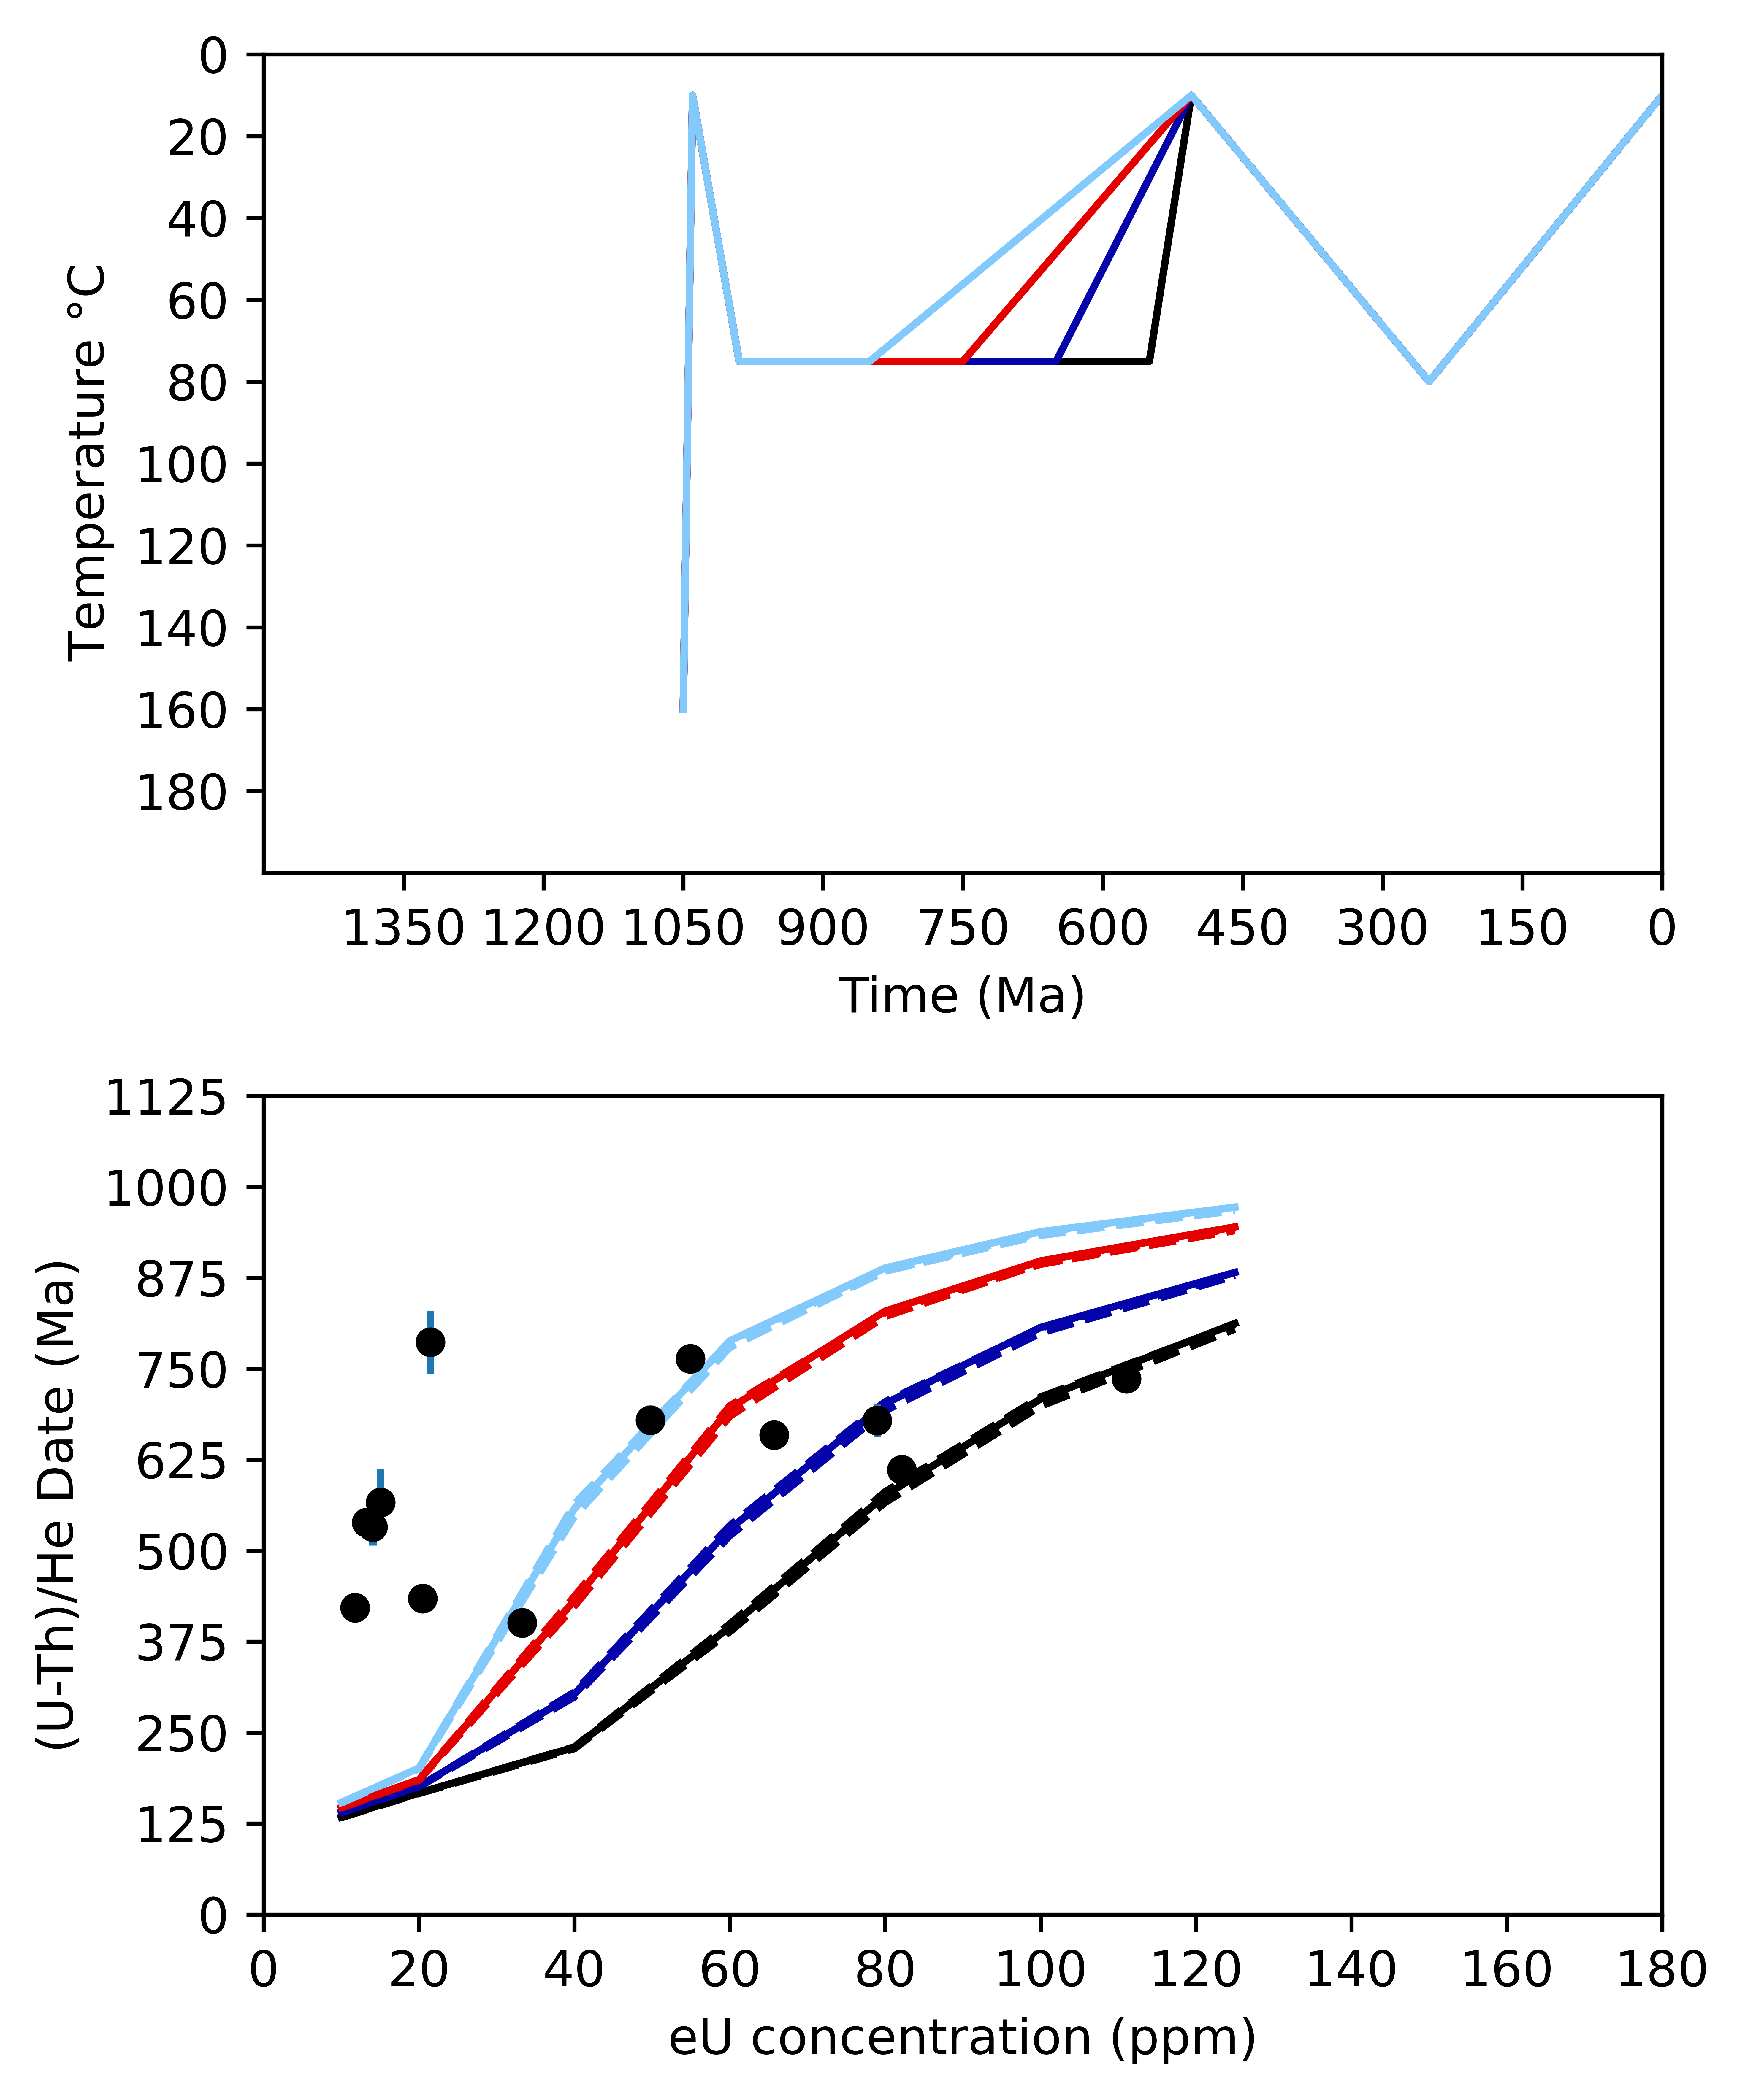

In [18]:
ap_neo_cool_path = pyt.tT_model(ap_grain_in,tT_ap_neo_cool,ap_obs_data)
ap_neo_cool_fig = ap_neo_cool_path.forward(log2_nodes=7)

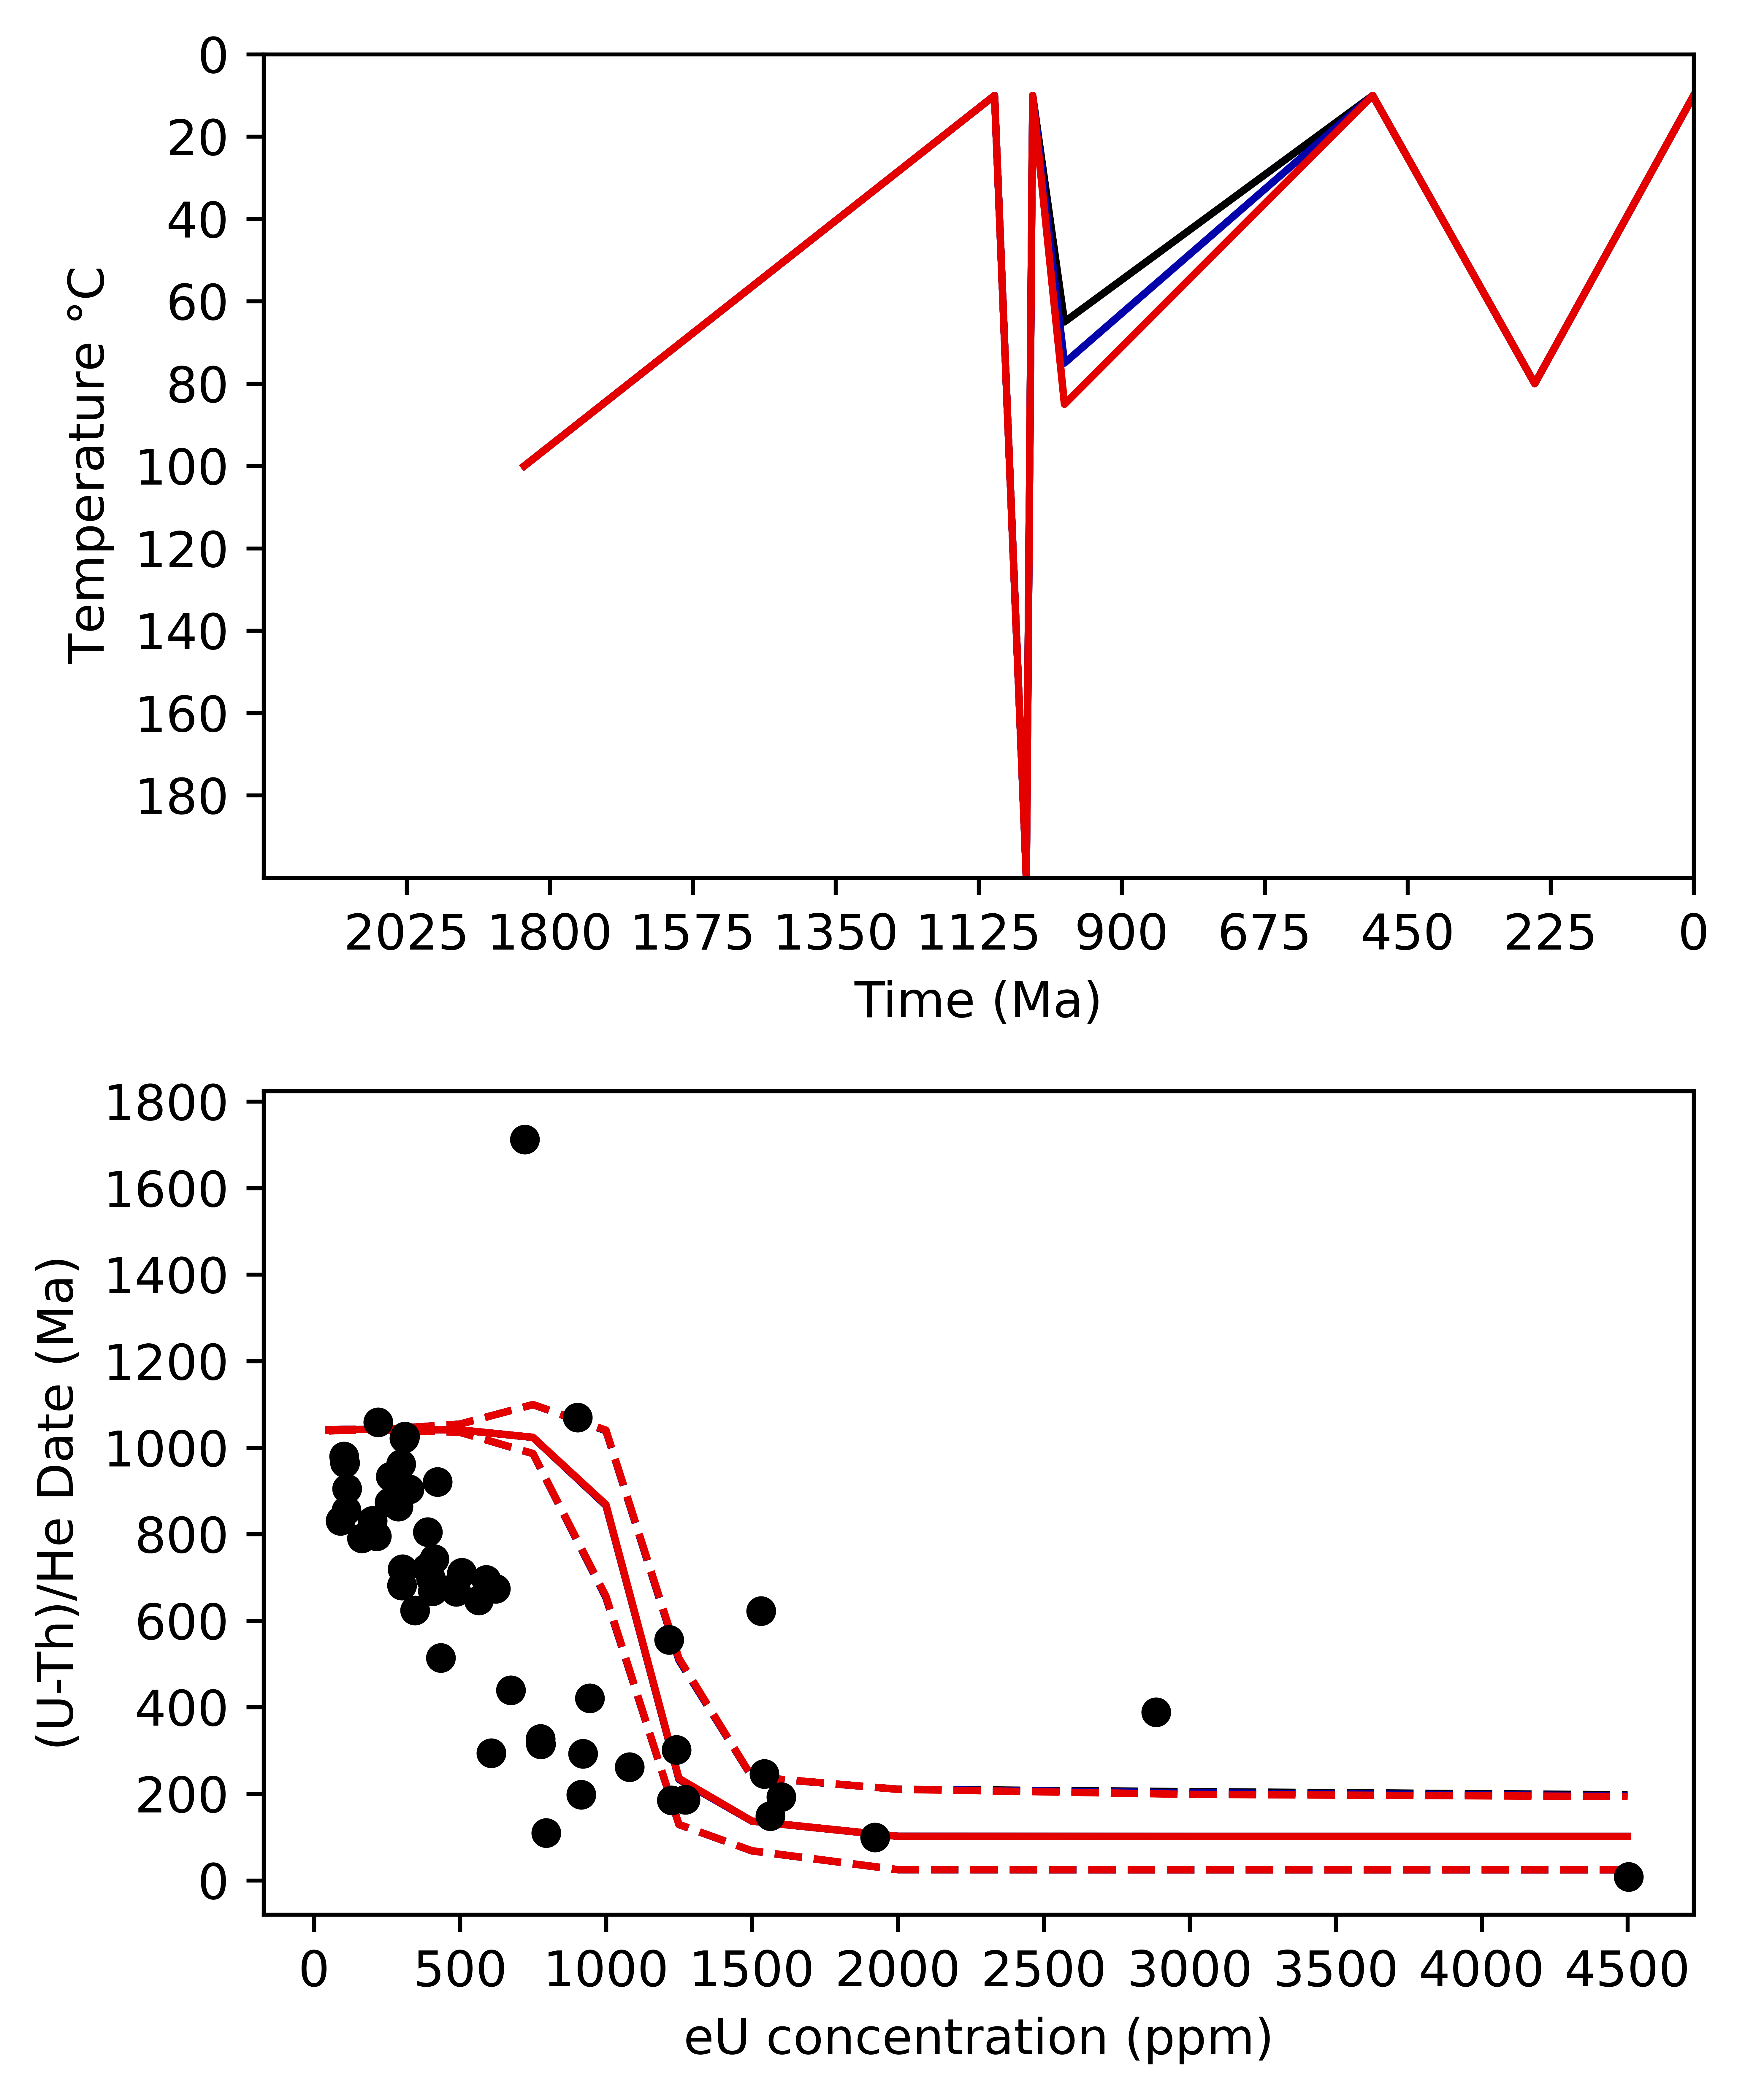

In [10]:
zirc_neo_heat_path = pyt.tT_model(zirc_grain_in,tT_zirc_neo_heat,zirc_obs_data)
zirc_neo_heat_fig = zirc_neo_heat_path.forward(log2_nodes=7)

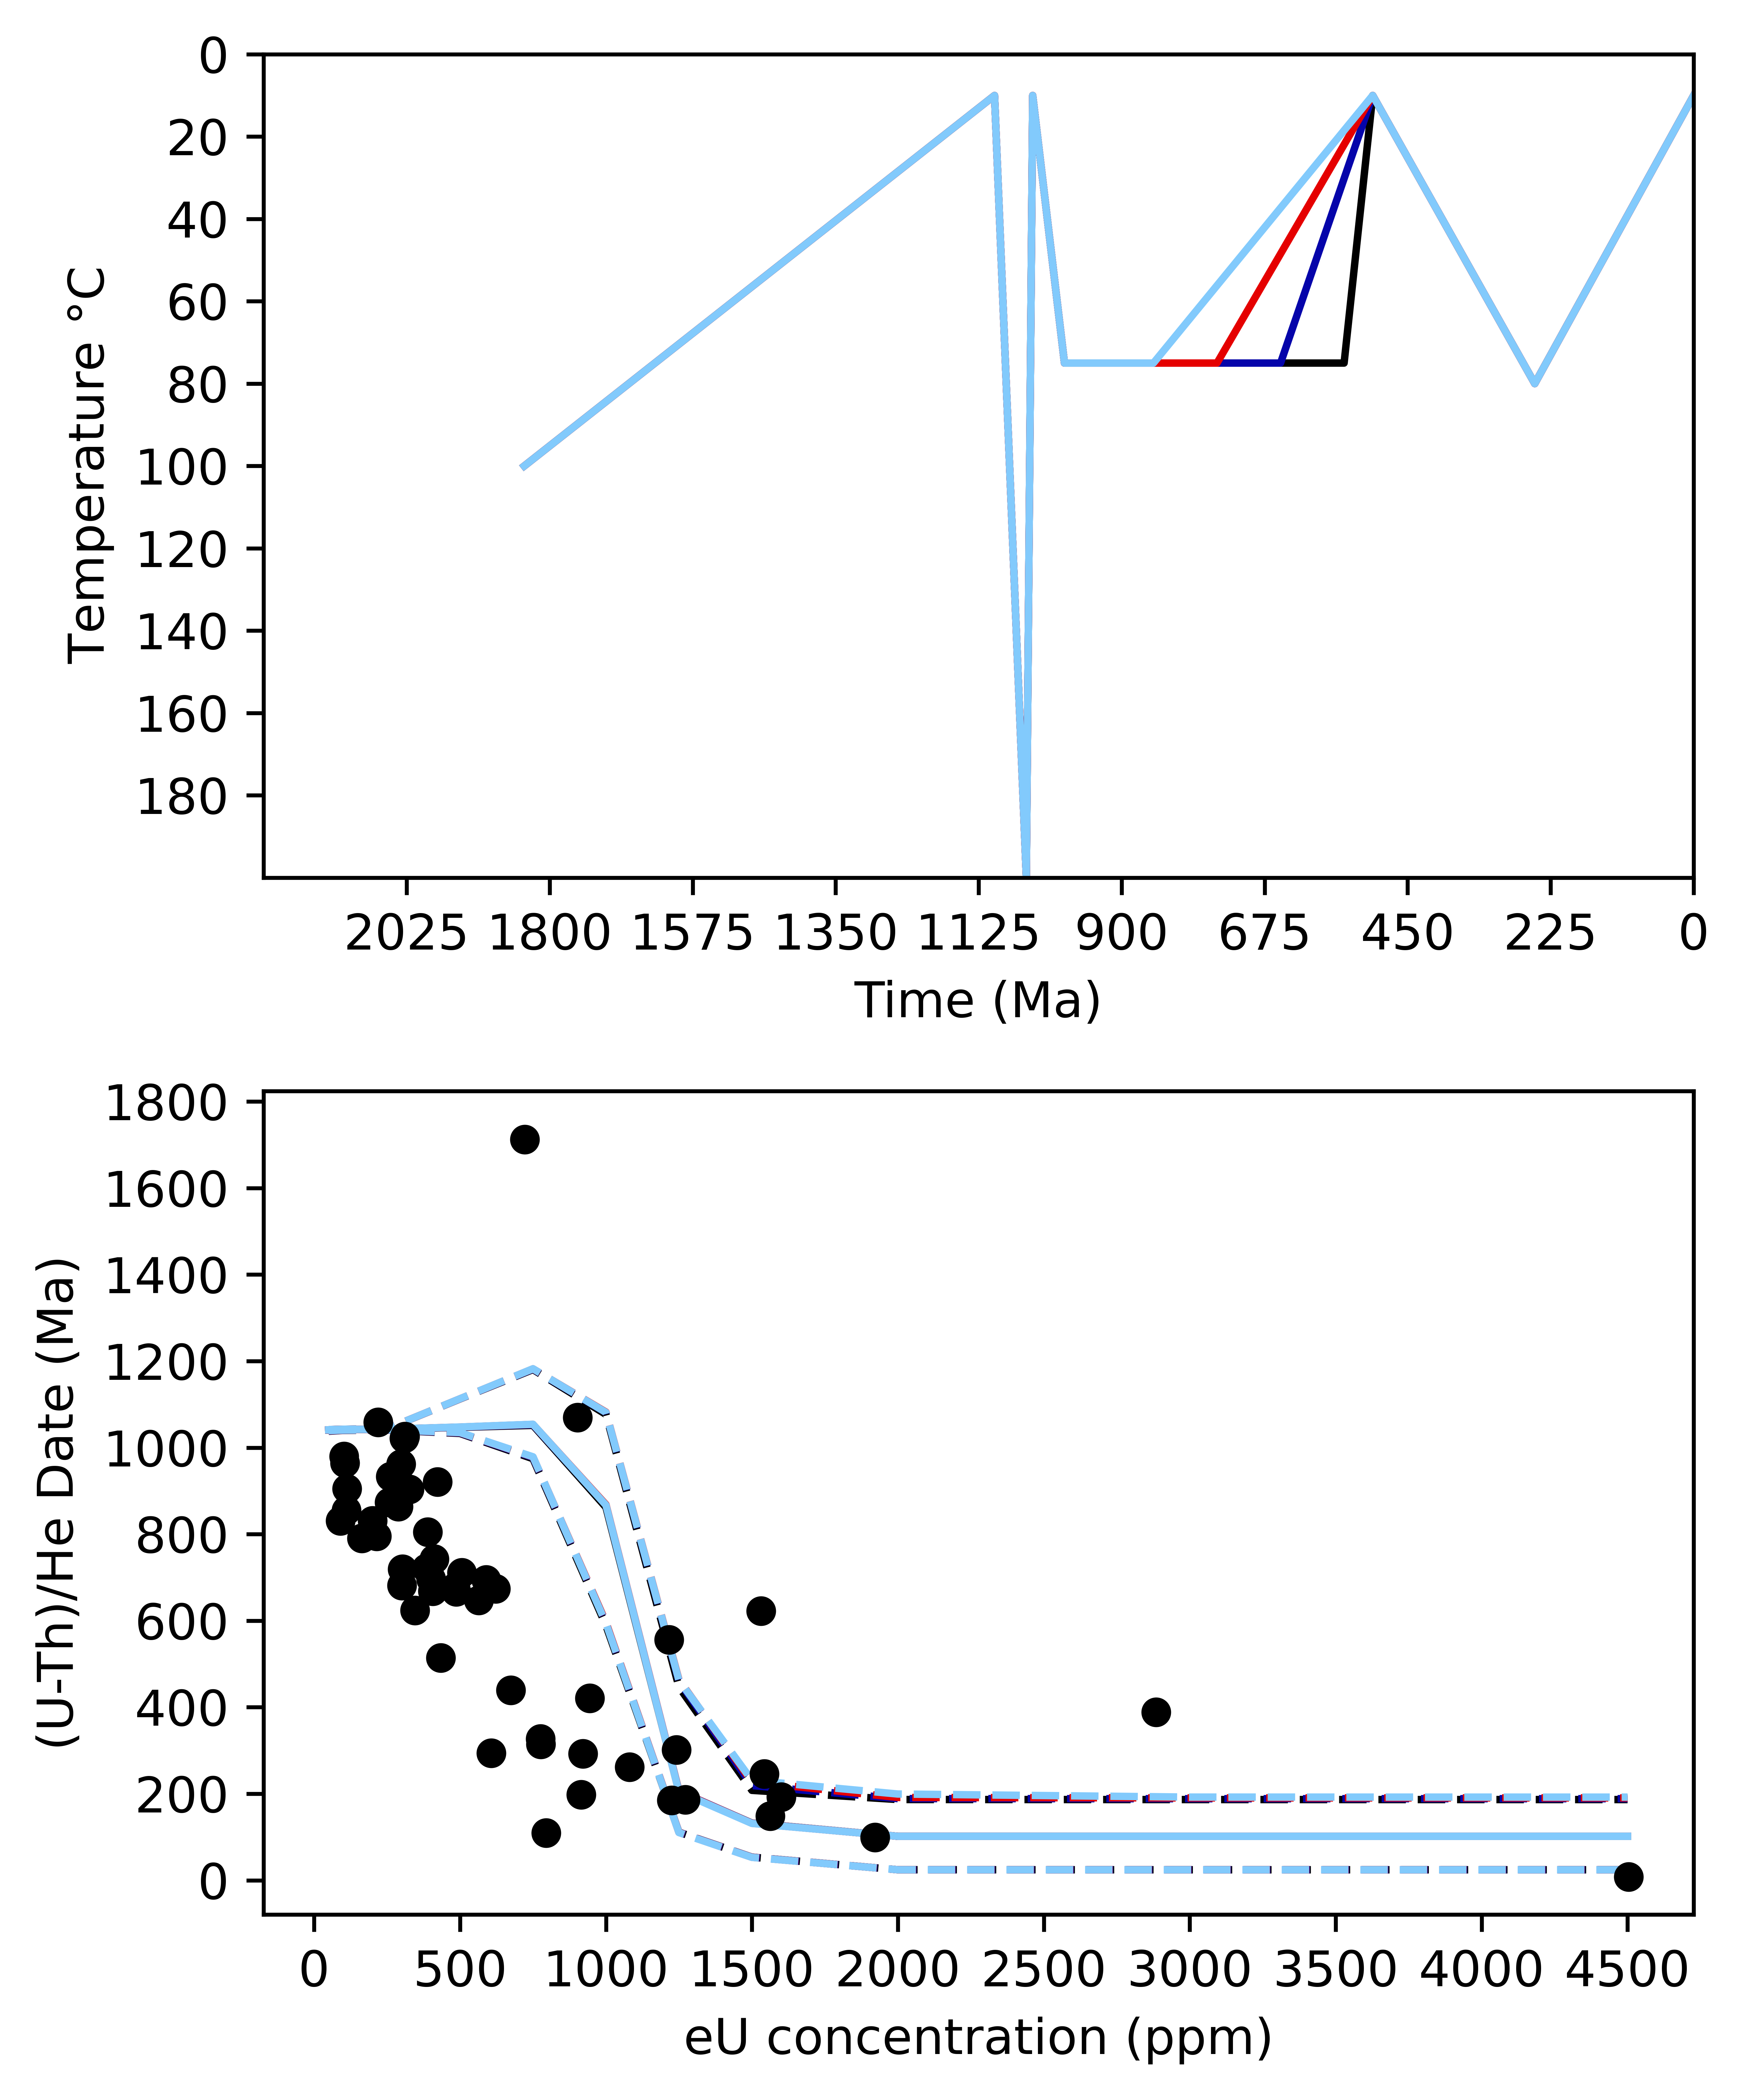

In [19]:
zirc_neo_cool_path = pyt.tT_model(zirc_grain_in,tT_zirc_neo_cool,zirc_obs_data)
zirc_neo_cool_fig = zirc_neo_cool_path.forward(log2_nodes=7)

Format and save the figures

In [21]:
ap_temp_max = 160
ap_age_max = 1200
ap_date_max = 1200
ap_eU_max = 140
ap_eU_step = 20

zirc_temp_max = 200
zirc_age_max = 2000
zirc_date_max = 1251
zirc_eU_max = 4501
zirc_eU_step = 500

def fig_format(fig, temp_max, age_max, date_max, eU_max, eU_step, file_name):
    ax_1 = fig.axes[0]
    ax_1.autoscale()
    ax_1.set_xlim(right=0)
    ax_1.xaxis.set_ticks(np.arange(age_max,-1,-200))
    ax_1.yaxis.set_ticks(np.arange(temp_max,-1,-20))
    ax_1.tick_params(axis='both', which='major', labelsize=11, direction='in') 
    ax_1.tick_params(axis='y', which='both', left=True, right=True)

    ax_2 = fig.axes[1]
    ax_2.autoscale()
    ax_2.set_ylim(top=date_max)
    ax_2.xaxis.set_ticks(np.arange(0,eU_max,eU_step))
    ax_2.yaxis.set_ticks(np.arange(0,date_max,250))
    ax_2.tick_params(axis='both', which='major', labelsize=11, direction='in') 
    ax_2.tick_params(axis='y', which='both', left=True, right=True)

    file_name = 'figures/' + file_name + '.pdf'
    fig.savefig(file_name,bbox_inches='tight')

fig_format(ap_neo_heat_fig, ap_temp_max, ap_age_max, ap_date_max, ap_eU_max, ap_eU_step, 'ap_neo_heat')
fig_format(ap_neo_cool_fig, ap_temp_max, ap_age_max, ap_date_max, ap_eU_max, ap_eU_step, 'ap_neo_cool')
fig_format(zirc_neo_heat_fig, zirc_temp_max, zirc_age_max, zirc_date_max, zirc_eU_max, zirc_eU_step, 'zirc_neo_heat')
fig_format(zirc_neo_cool_fig, zirc_temp_max, zirc_age_max, zirc_date_max, zirc_eU_max, zirc_eU_step, 'zirc_neo_cool')


The next four cells below follow the same procedure for the Phanerozoic tests.

A sub-set of Phanerozoic forward model tests.

In [22]:
#apatite tT paths

tT_ap_phan = np.array([[0,10,0,10,0,10,0,10],[250,75,250,80,250,85,250,90],[505,10,505,10,505,10,505,10],[990,75,990,75,990,75,990,75],[1040,10,1040,10,1040,10,1040,10],[1050,160,1050,160,1050,160,1050,160],])

#zircon tT paths

tT_zirc_phan = np.array([[0,10,0,10,0,10,0,10],[250,80,250,100,250,120,250,140],[505,10,505,10,505,10,505,10],[990,75,990,75,990,75,990,75],[1040,10,1040,10,1040,10,1040,10],[1050,200,1050,200,1050,200,1050,200],[1100,10,1100,10,1100,10,1100,10],[1840,100,1840,100,1840,100,1840,100]])

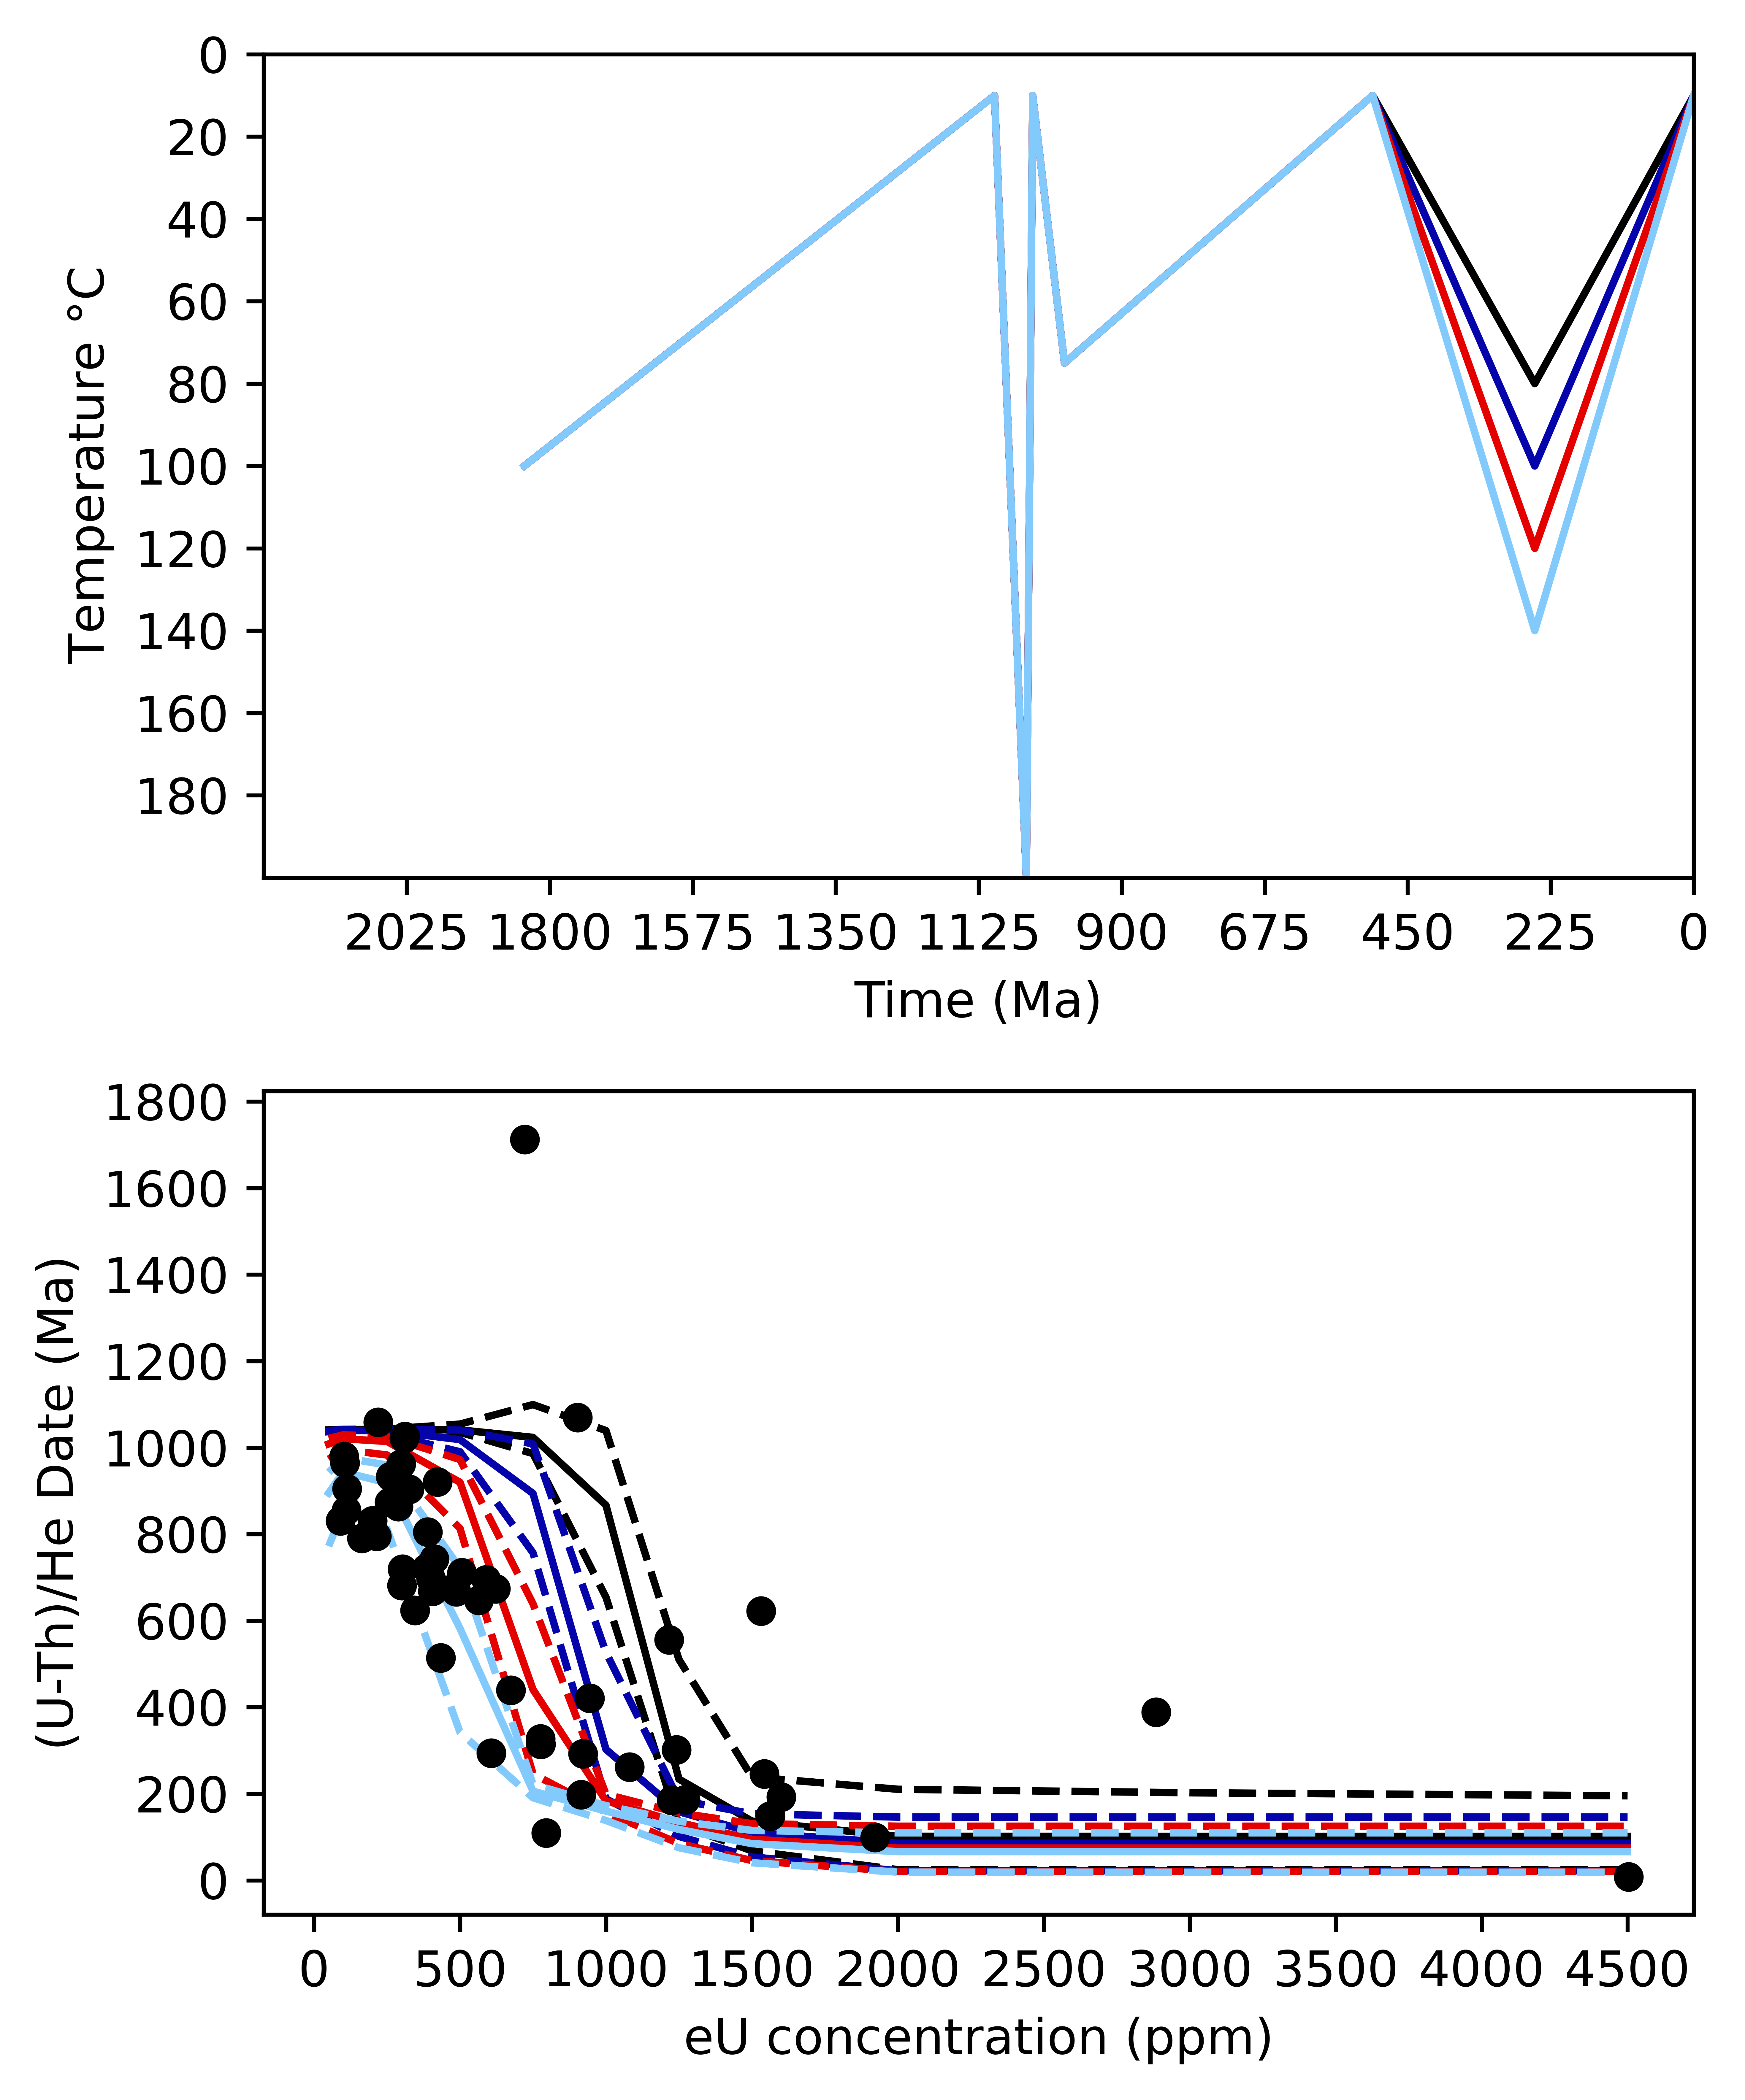

In [24]:
zirc_phan_path = pyt.tT_model(zirc_grain_in,tT_zirc_phan,zirc_obs_data)
zirc_phan_fig = zirc_phan_path.forward(log2_nodes=7)

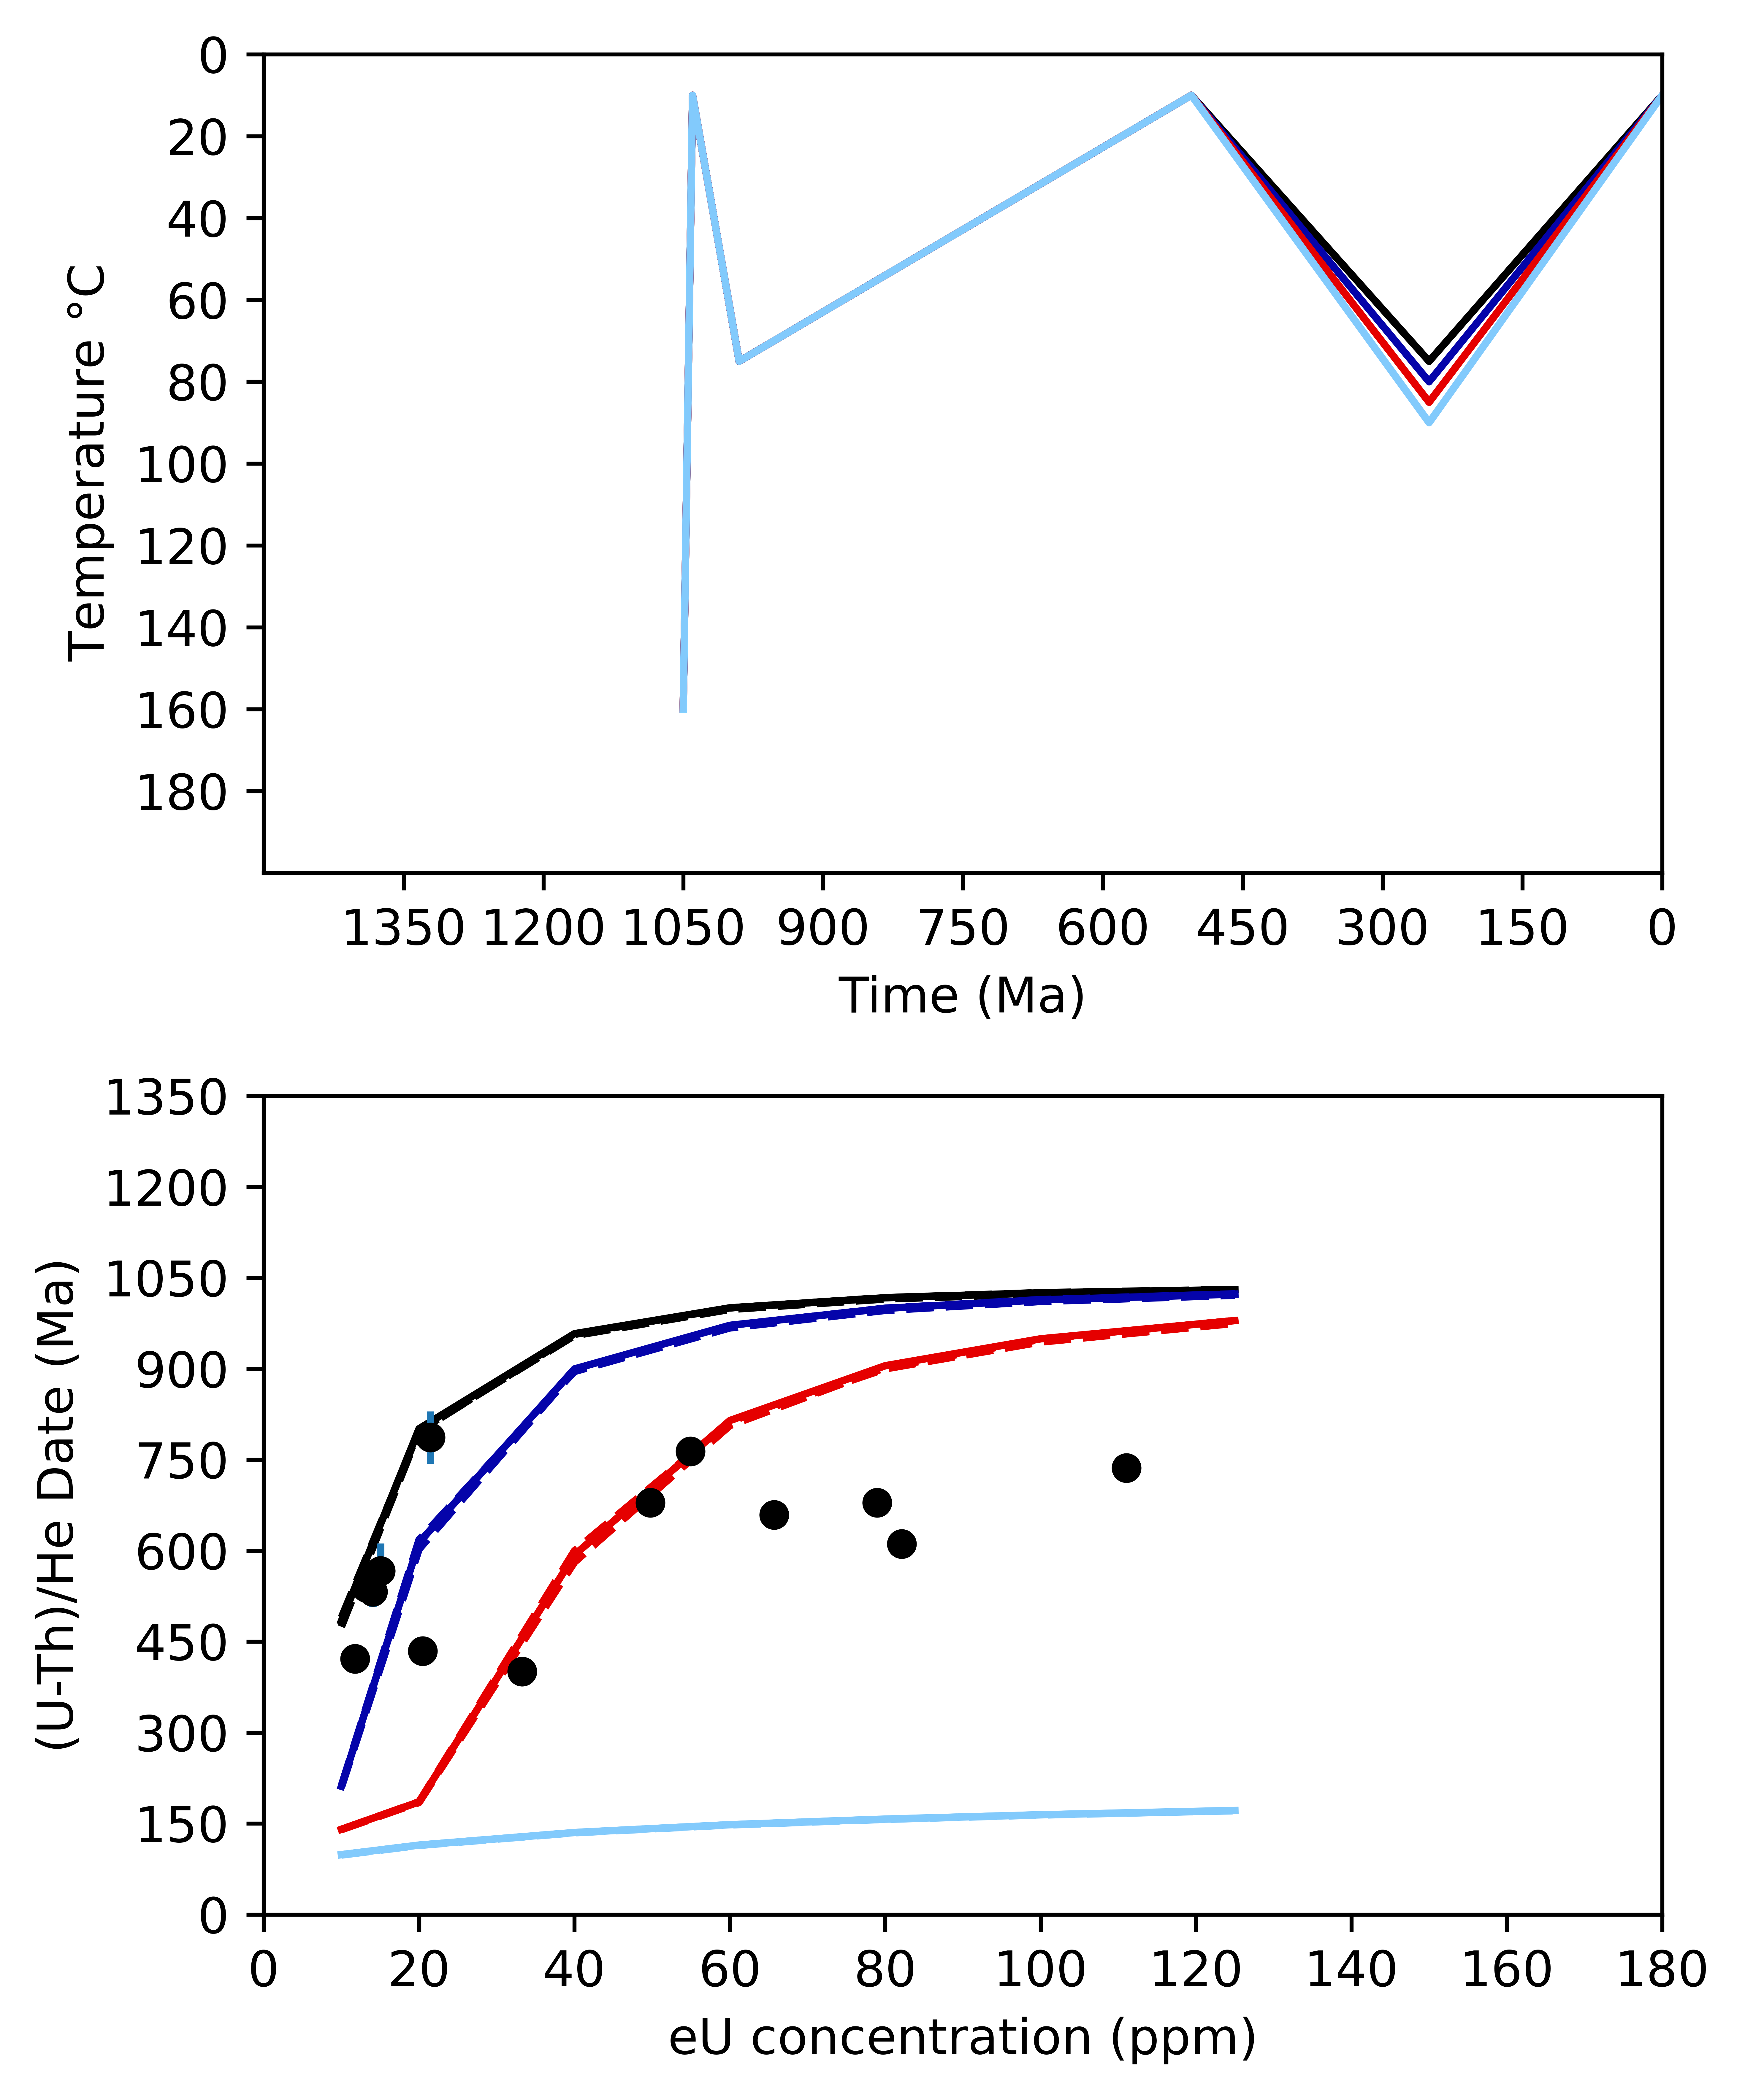

In [25]:
ap_phan_path = pyt.tT_model(ap_grain_in,tT_ap_phan,ap_obs_data)
ap_phan_fig = ap_phan_path.forward(log2_nodes=7)

In [26]:
fig_format(ap_phan_fig, ap_temp_max, ap_age_max, ap_date_max, ap_eU_max, ap_eU_step, 'ap_phan')
fig_format(zirc_phan_fig, zirc_temp_max, zirc_age_max, zirc_date_max, zirc_eU_max, zirc_eU_step, 'zirc_phan')